In [3]:
import torch
import torchvision
from PIL import Image
import numpy as np

# Load the image
image_path = "example_4.jpeg"
img = Image.open(image_path)
img = img.convert('RGB')
device = torch.device("mps" if torch.backends.mps.is_available() else "cuda")


# Resize the input tensor to match the model's expected input size
input_size = 224  # Standard input size for ResNet-50
transform = torchvision.transforms.Compose([
    torchvision.transforms.ToTensor(),
    #torchvision.transforms.Resize((input_size, input_size)),
    #torchvision.transforms.CenterCrop(input_size),
])

input_tensor = transform(img)

In [2]:
%matplotlib inline

In [4]:
y_at_linf_8_no_attack = [48.6, 48.6, 48.6, 48.6, 48.6, 48.6, 48.6]
y_at_linf_8_linf_8_attack = [21.5, 21.5, 21.5, 21.5, 21.5, 21.5, 21.5]
y_at_linf_8_l2_5_attack = [3.47,3.47,3.47,3.47,3.47,3.47,3.47]
y_at_linf_8_linf_16_attack = [5.6,5.6,5.6,5.6,5.6,5.6,5.6]

#Attack: AutoAttack(model_name=ResNet, device=mps, attack_mode=default, targeted=False, normalization_used=True, norm=Linf, eps=0.03137254901960784, version=plus, n_classes=1000, seed=None, verbose=False)
#Accuracies: dict_items([(0.0, 27.9540273556231), (0.4, 52.080167173252285), (0.5, 57.798252279635264), (0.6, 58.19718844984803), (0.7, 57.33282674772037), (0.8, 49.76253799392097), (0.9, 25.0)])
y_linf_auto_attack = [27.9540273556231, 52.080167173252285, 57.798252279635264, 58.19718844984803, 57.33282674772037, 49.76253799392097, 25.0]

#Attack: FGSM(model_name=ResNet, device=mps, attack_mode=default, targeted=False, normalization_used=True, eps=0.03137254901960784)
#Accuracies: dict_items([(0.0, 56.08852583586626), (0.4, 59.08054711246201), (0.5, 59.84992401215805), (0.6, 58.82408814589665), (0.7, 57.807750759878424), (0.8, 51.33928571428571), (0.9, 24.420592705167174)])
y_fgsm_8 = [56.08852583586626, 59.08054711246201, 59.84992401215805, 58.82408814589665, 57.807750759878424, 51.33928571428571, 24.420592705167174]
y_at_linf_8_fgsm_8 = [22.21, 22.21, 22.21, 22.21, 22.21, 22.21, 22.21]

#Attack: Jitter(model_name=ResNet, device=mps, attack_mode=default, targeted=False, normalization_used=True, eps=0.03137254901960784, alpha=0.00784313725490196, steps=10, random_start=True, scale=10, std=0.1)
#Accuracies: dict_items([(0.0, 16.43237082066869), (0.4, 49.487082066869306), (0.5, 53.59992401215805), (0.6, 59.15653495440729), (0.7, 59.204027355623104), (0.8, 50.503419452887535), (0.9, 26.03533434650456)])

y_jiter_linf_8 = [16.43237082066869, 49.487082066869306, 53.59992401215805, 59.15653495440729, 59.204027355623104, 50.503419452887535, 26.03533434650456]
#Attack: CW(model_name=RestNet, device=cuda:3, attack_mode=default, targeted=False, normalization_used=True, c=1, kappa=0, steps=10, lr=0.01)
y_cw = [ 58.56261322463768, 68.04800724637681, 67.95742753623189, 67.5583106884058 ,64.96546648550725,  53.26936141304348, 25.625566123188406]
#Attack: PGD(model_name=ResNet, device=cuda:3, attack_mode=default, targeted=False, normalization_used=True, eps=0.01568627450980392, alpha=0.00784313725490196, steps=10, random_start=False)
#Accuracies: dict_items([(0.0, 40.51460597826087), (0.4, 60.869565217391305), (0.5, 63.439764492753625), (0.6, 63.87284873188406), (0.7, 60.580842391304344), (0.8, 51.6983695652174), (0.9, 25.47271286231884)])

#dict_items([(0.0, 58.56261322463768), (0.4, 68.04800724637681), (0.5, 67.95742753623189), (0.6, 67.5583106884058), (0.7, 64.96546648550725), (0.8, 53.26936141304348), (0.9, 25.625566123188406)])

# Attack: PIFGSMPP(model_name=ResNet, device=cuda:3, attack_mode=default, targeted=False, normalization_used=True, max_epsilon=0.06274509803921569, num_iter_set=10, momentum=1.0, amplification=10.0, prob=0.7, project_factor=0.8).
# Accuracies: dict_items([(0.0, 2.127659574468085), (0.4, 4.720744680851064), (0.5, 7.579787234042553), (0.6, 11.037234042553191), (0.7, 15.757978723404255), (0.8, 19.81382978723404), (0.9, 14.49468085106383)])
# Noise patch = 5
#dict_items([(0.4, 10.571808510638299), (0.5, 14.361702127659575), (0.6, 16.356382978723403), (0.7, 18.15159574468085), (0.8, 18.949468085106382), (0.9, 17.819148936170212)])
#Attack: PIFGSMPP(model_name=ResNet, device=cuda:3, attack_mode=default, targeted=False, normalization_used=True, max_epsilon=0.06274509803921569, num_iter_set=10, momentum=1.0, amplification=10.0, prob=0.7, project_factor=0.8).
#Accuracies: dict_items([(0.4, 12.433510638297872), (0.5, 14.76063829787234), (0.6, 16.356382978723403), (0.7, 17.61968085106383), (0.8, 15.02659574468085), (0.9, 13.497340425531915)])
#Attack: PIFGSMPP(model_name=ResNet, device=cuda:3, attack_mode=default, targeted=False, normalization_used=True, max_epsilon=0.03137254901960784, num_iter_set=10, momentum=1.0, amplification=10.0, prob=0.7, project_factor=0.8).
#Accuracies: dict_items([(0.0, 8.06725543478261), (0.4, 19.84544836956522), (0.5, 24.61503623188406), (0.6, 30.440443840579707), (0.7, 36.0252490942029), (0.8, 37.296195652173914), (0.9, 21.84952445652174)])

# Tucker, rank = 20, steps = 20
# torchattacks.PGD(torch.nn.Module(), eps=4/255, alpha=2/255, random_start=False, steps=10)
# dict_items([(0.4, 62.16755319148936), (0.5, 59.973404255319146), (0.6, 54.055851063829785), (0.7, 45.47872340425532), (0.8, 34.04255319148936)])




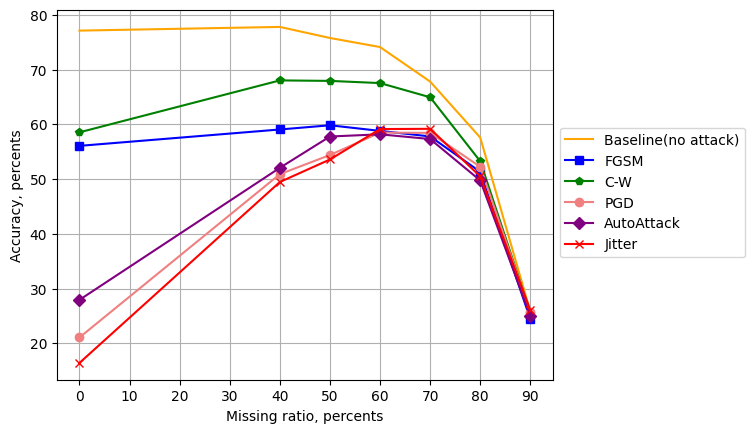

/var/folders/sl/3jv_kqln19l3zyln__6qgfdm0000gn/T/ipykernel_81397/1125828817.py:36: MatplotlibDeprecationWarning: savefig() got unexpected keyword argument "facecolor" which is no longer supported as of 3.3 and will become an error two minor releases later
  fig.savefig('Attacks vs Noise.png',)
/var/folders/sl/3jv_kqln19l3zyln__6qgfdm0000gn/T/ipykernel_81397/1125828817.py:36: MatplotlibDeprecationWarning: savefig() got unexpected keyword argument "edgecolor" which is no longer supported as of 3.3 and will become an error two minor releases later
  fig.savefig('Attacks vs Noise.png',)
/var/folders/sl/3jv_kqln19l3zyln__6qgfdm0000gn/T/ipykernel_81397/1125828817.py:36: MatplotlibDeprecationWarning: savefig() got unexpected keyword argument "orientation" which is no longer supported as of 3.3 and will become an error two minor releases later
  fig.savefig('Attacks vs Noise.png',)
/var/folders/sl/3jv_kqln19l3zyln__6qgfdm0000gn/T/ipykernel_81397/1125828817.py:36: MatplotlibDeprecationWarning: 

In [8]:
import matplotlib.pyplot as plt
import numpy as np
noise_percents = [0, 40, 50, 60, 70, 80, 90]
y_no = [77.14460784313725, 77.81862745098039, 75.79656862745098, 74.1421568627451, 67.83088235294117, 57.59803921568628, 25.79656862745098]
y_linf = [21.07843137254902, 50.919117647058826, 54.411764705882355, 58.5171568627451, 58.455882352941174, 52.2671568627451, 25.735294117647058]
y_linf_strong = [14.705882352941176, 48.713235294117645, 50.18382352941177, 51.77696078431372, 51.22549019607843, 43.872549019607845, 20.71078431372549]
y_2 = [20.34313725490196, 49.93872549019608, 55.02450980392157, 56.127450980392155, 58.76225490196079, 51.16421568627451, 24.019607843137255]
y_no_attack_no_filt = [79.90196078431373, 74.08088235294117, 61.15196078431372, 37.193627450980394, 14.950980392156863, 3.7377450980392157, 0.8578431372549019]
y_no_attack_no_restore = [80.40463525835867, 53.808890577507604, 43.6265197568389, 32.75075987841945, 17.990121580547115, 6.117021276595745, 0.9403495440729482]
fig, ax = plt.subplots()
major_ticks = np.arange(0, 91, 10)
ax.set_xticks(major_ticks)

ax.plot(noise_percents, y_no, label='Baseline(no attack)', color='orange')
#ax.plot(noise_percents, y_no_attack_no_restore, label='Without restoration', color='gray', linestyle='-.')
#ax.plot(noise_percents, y_no_attack_no_filt, label='no filter', color='lightgreen')
#ax.plot(noise_percents, y_at_linf_8_no_attack, label="No attack(AT)", linestyle='dashed', color='green')
ax.plot(noise_percents, y_fgsm_8, label='FGSM', color='blue', marker='s')
ax.plot(noise_percents, y_cw, label = "C-W", color='green', marker='p')
#ax.plot(noise_percents, y_at_linf_8_fgsm_8, label='FGSM attack, eps=8/255(AT)', linestyle='dashed', color='lightblue')
ax.plot(noise_percents, y_linf, label='PGD', color = 'lightcoral', marker='o')
#ax.plot(noise_percents, y_at_linf_8_linf_8_attack, label="PGD-L∞ attack, eps=8/255 (AT)", linestyle='dashed', color='red')
#ax.plot(noise_percents, y_2, label='PGD-L2 attack, eps=5', color='springgreen')
#ax.plot(noise_percents,y_at_linf_8_l2_5_attack , label='PGD-L2 attack, eps=5 (AT)', color='olive', linestyle='dashed')
#ax.plot(noise_percents, y_linf_strong, label='PGD L∞ attack, eps=16/255', color='olive')
#ax.plot(noise_percents, y_at_linf_8_linf_16_attack, label='PGD L∞ attack, eps=16/255 (AT)', linestyle='dashed', color='pink')
ax.plot(noise_percents, y_linf_auto_attack, label = "AutoAttack", color='purple', marker="D")
ax.plot(noise_percents, y_jiter_linf_8, label = "Jitter", color='red', marker="x")
ax.set_xlabel('Missing ratio, percents')
ax.set_ylabel('Accuracy, percents')
#ax.set_title('ResNet-50 on ImageNet dataset')
fig.legend(loc='center left', bbox_to_anchor=(0.9, 0.5))

plt.grid()
plt.show()
fig.savefig('Attacks vs Noise.png',)

/opt/homebrew/lib/python3.11/site-packages/IPython/core/pylabtools.py:152: MatplotlibDeprecationWarning: savefig() got unexpected keyword argument "orientation" which is no longer supported as of 3.3 and will become an error two minor releases later
  fig.canvas.print_figure(bytes_io, **kw)
/opt/homebrew/lib/python3.11/site-packages/IPython/core/pylabtools.py:152: MatplotlibDeprecationWarning: savefig() got unexpected keyword argument "facecolor" which is no longer supported as of 3.3 and will become an error two minor releases later
  fig.canvas.print_figure(bytes_io, **kw)
/opt/homebrew/lib/python3.11/site-packages/IPython/core/pylabtools.py:152: MatplotlibDeprecationWarning: savefig() got unexpected keyword argument "edgecolor" which is no longer supported as of 3.3 and will become an error two minor releases later
  fig.canvas.print_figure(bytes_io, **kw)
/opt/homebrew/lib/python3.11/site-packages/IPython/core/pylabtools.py:152: MatplotlibDeprecationWarning: savefig() got unexpecte

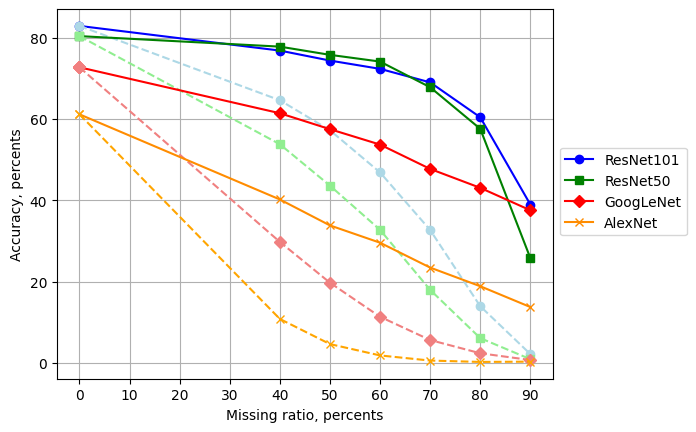

In [1]:
import matplotlib.pyplot as plt
import numpy as np
noise_percents = [0, 40, 50, 60, 70, 80, 90]
fig, ax = plt.subplots()
major_ticks = np.arange(0, 91, 10)
ax.set_xticks(major_ticks)

# ResNet50 with restoration
# 77.14460784313725
y_resnet50 = [80.40463525835867, 77.81862745098039, 75.79656862745098, 74.1421568627451, 67.83088235294117, 57.59803921568628, 25.79656862745098]
y_resnet50_rank10 = [80.2309, 65.1495, 60.0487, 54.5658, 49.1168, 42.3319, 34.7345]
y_resnet50_rank100 = [80.103, 70.1087, 66.0326, 61.4017, 57.7417, 51.7012, 46.2777]
dict_items([(0.0, 80.10360054347827), (0.4, 70.10869565217392), (0.5, 66.03260869565217), (0.6, 61.40172101449275), (0.7, 57.741734601449274), (0.8, 51.701200181159415), (0.9, 46.27774003623188)])
# ResNet50 without restoration
y_resnet50_no_rest = [80.40463525835867, 53.808890577507604, 43.6265197568389, 32.75075987841945, 17.990121580547115, 6.117021276595745, 0.9403495440729482]

# ResNet101 with restoration
# 79.73845108695652
y_resnet101 = [82.9122340425532 , 76.84839221014492, 74.38858695652173, 72.35054347826087, 69.02456974637681, 60.4393115942029, 38.97758152173913]
# ResNet101 without restoration
y_resnet101_no_rest = [82.9122340425532, 64.62765957446808, 57.24734042553192, 46.875, 32.712765957446805, 13.962765957446809, 2.1941489361702127]

# Alexnet with restoration
54.72074468085106
y_alexnet = [61.170212765957444, 40.226063829787236, 33.84308510638298, 29.58776595744681, 23.470744680851062, 18.882978723404257, 13.763297872340425]
# Alexnet without restoration
y_alexnet_no_rest = [61.170212765957444, 10.837765957446809, 4.654255319148936, 1.8617021276595744, 0.598404255319149, 0.26595744680851063, 0.3324468085106383]

# googlenet with restoration
# 68.15159574468085
y_googlenet = [72.73936170212765, 61.43617021276596, 57.513297872340424, 53.723404255319146, 47.73936170212766, 43.08510638297872, 37.566489361702125]
# googlenet without restoration
y_googlenet_no_rest = [ 72.73936170212765, 29.78723404255319, 19.747340425531913, 11.36968085106383, 5.651595744680851, 2.393617021276596, 0.7313829787234043]

ax.plot(noise_percents, y_resnet101, label="ResNet101", color="blue", marker='o')
ax.plot(noise_percents, y_resnet101_no_rest, color="lightblue", linestyle='dashed', marker='o')

ax.plot(noise_percents, y_resnet50, label="ResNet50", color="green", marker='s')
ax.plot(noise_percents, y_resnet50_no_rest, color="lightgreen", linestyle='dashed', marker='s')

ax.plot(noise_percents, y_googlenet, label="GoogLeNet", color="red", marker='D')
ax.plot(noise_percents, y_googlenet_no_rest, color="lightcoral", linestyle='dashed', marker='D')

ax.plot(noise_percents, y_alexnet, label="AlexNet", color="darkorange", marker='x')
ax.plot(noise_percents, y_alexnet_no_rest, color="orange", linestyle='dashed', marker='x')


ax.set_xlabel('Missing ratio, percents')
ax.set_ylabel('Accuracy, percents')
#ax.set_title('ResNet-50 on ImageNet dataset')
fig.legend(loc='center left', bbox_to_anchor=(0.9, 0.5))

plt.grid()
plt.show()
#fig.savefig('Attacks vs Noise.png')

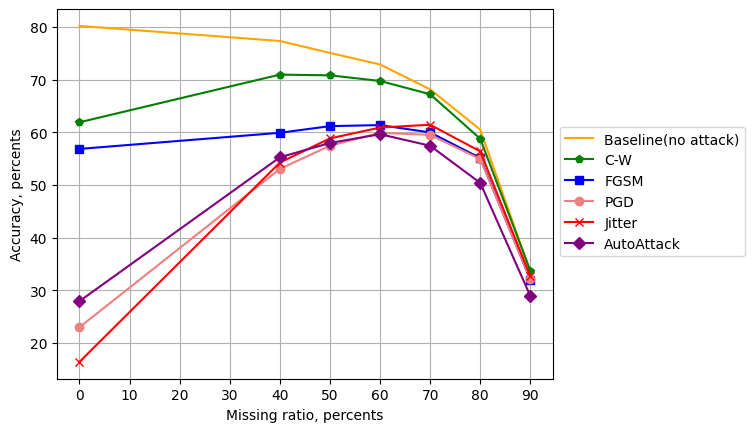

In [26]:
# Resnet50 tucker 58, 30 steps 
import matplotlib.pyplot as plt
import numpy as np
noise_percents = [0, 40, 50, 60, 70, 80, 90]
fig, ax = plt.subplots()
major_ticks = np.arange(0, 91, 10)
ax.set_xticks(major_ticks)

y_tucker_baseline = [80.18617021276596, 77.32712765957447, 75.06648936170212, 72.87234042553192, 68.15159574468085, 60.505319148936174, 33.51063829787234]

# Attack: AutoAttack(model_name=ResNet, device=cpu, attack_mode=default, targeted=False, normalization_used=True, norm=Linf, eps=0.03137254901960784, version=plus, n_classes=1000, seed=None, verbose=False).
y_tucker_autoattack = [27.9540273556231, 55.25265957446808, 57.97872340425532, 59.640957446808514, 57.4468085106383, 50.398936170212764, 28.92287234042553]

# Attack: Jitter(model_name=ResNet, device=cpu, attack_mode=default, targeted=False, normalization_used=True, eps=0.03137254901960784, alpha=0.00784313725490196, steps=10, random_start=True, scale=10, std=0.1).
y_tucker_jitter = [16.43237082066869, 54.255319148936174, 58.84308510638298, 60.90425531914894, 61.43617021276596, 56.38297872340426, 32.64627659574468]

#  Attack: FGSM(model_name=ResNet, device=cpu, attack_mode=default, targeted=False, normalization_used=True, eps=0.03137254901960784).
y_tucker_fgsm = [56.848404255319146, 59.90691489361702, 61.170212765957444, 61.369680851063826, 59.973404255319146, 55.119680851063826, 32.047872340425535]

# Attack: PGD(model_name=ResNet, device=cpu, attack_mode=default, targeted=False, normalization_used=True, eps=0.03137254901960784, alpha=0.00784313725490196, steps=10, random_start=False).
y_tucker_pgd = [23.00531914893617, 53.058510638297875, 57.4468085106383, 59.90691489361702, 59.50797872340426, 54.920212765957444, 32.11436170212766]

#Attack: CW(model_name=ResNet, device=cpu, attack_mode=default, targeted=False, normalization_used=True, c=1, kappa=0, steps=50, lr=0.01).
y_tucker_cw = [61.901595744680854, 70.94414893617021, 70.81117021276596, 69.74734042553192, 67.22074468085107, 58.776595744680854, 33.71010638297872]

ax.plot(noise_percents, y_tucker_baseline, label='Baseline(no attack)', color='orange')
ax.plot(noise_percents, y_tucker_cw, label = "C-W", color='green', marker='p')
ax.plot(noise_percents, y_tucker_fgsm, label='FGSM', color='blue', marker='s')
ax.plot(noise_percents, y_tucker_pgd, label='PGD', color = 'lightcoral', marker='o')
ax.plot(noise_percents, y_tucker_jitter, label = "Jitter", color='red', marker="x")
ax.plot(noise_percents, y_tucker_autoattack, label = "AutoAttack", color='purple', marker="D")


ax.set_xlabel('Missing ratio, percents')
ax.set_ylabel('Accuracy, percents')
#ax.set_title('ResNet-50 on ImageNet dataset')
fig.legend(loc='center left', bbox_to_anchor=(0.9, 0.5))

plt.grid()
plt.show()


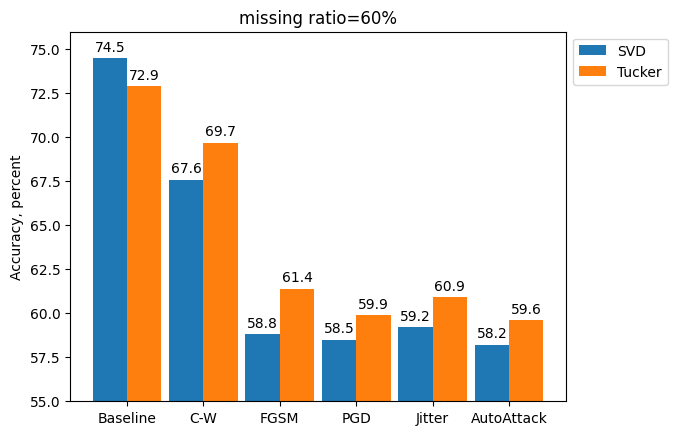

In [38]:

import matplotlib.pyplot as plt
import numpy as np

species = ("Baseline", "C-W", "FGSM", "PGD", "Jitter", "AutoAttack")
penguin_means = {
    'SVD': (74.5, 67.6, 58.8, 58.5,  59.2, 58.2),
    'Tucker': (72.9, 69.7, 61.4, 59.9, 60.9, 59.6)
}

x = np.arange(len(species))  # the label locations
width = 0.45  # the width of the bars
multiplier = -0.5

fig, ax = plt.subplots()

for attribute, measurement in penguin_means.items():
    offset = width * multiplier
    rects = ax.bar(x + offset, measurement, width, label=attribute)
    ax.bar_label(rects, padding=3)
    multiplier += 1

# Add some text for labels, title and custom x-axis tick labels, etc.
ax.set_ylabel('Accuracy, percent')
ax.set_title('missing ratio=60%')
ax.set_xticks(np.arange(len(species)))
ax.set_xticklabels(species)
ax.legend(loc='upper left', bbox_to_anchor=(1, 1))
ax.set_ylim(55, 76)

plt.show()

In [55]:
input_tensor.shape

torch.Size([3, 256, 256])

In [4]:
import torchvision.models as models
import json


# Define the model and move it to GPU if available
model = models.resnet50(pretrained=True)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)
model.eval()

def predict(tensor):
    with open('imagenet-simple-labels.json') as f:
        labels = json.load(f)

    # Make predictions
    with torch.no_grad():
        outputs = model(tensor)

    # Get the predicted class and confidence
    _, predicted_class = torch.max(outputs, dim=1)
    confidence, _ = torch.max(outputs, dim=1)

    print(f"Predicted class: {labels[predicted_class.item()]}")
    return labels[predicted_class.item()]


/opt/homebrew/lib/python3.11/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/opt/homebrew/lib/python3.11/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet50_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet50_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


In [21]:
import numpy as np
from matplotlib import pyplot as plt


def generate_white_noise(img, ratio=0.01):
    height = img.shape[-2] 
    width = img.shape[-1]

    matrix = np.random.normal(0, ratio, size=(width,height))
    img += matrix
    return img.float()


def generate_salt_pepper_noise(img, ratio=0.001):
    # Create an array of ones
    height = img.shape[-2] 
    width = img.shape[-1]
    assert width == height
    matrix = np.ones((height,width))
    # Calculate how many elements we want to change to zero
    num_zeros = int(matrix.size * ratio)
    # Generate random indices where we want to change ones to zeros
    indices_to_change = np.random.choice(matrix.size, num_zeros, replace=False,)
    # Change ones to zeros at those indices
    matrix[indices_to_change // height,indices_to_change % height] = 0

    img *= matrix

    return img, matrix

def generate_patch_noise(img, square_percent=0.17):
    height = img.shape[-2] 
    width = img.shape[-1]
    square = width * height * square_percent
    patch_len = np.sqrt(square)

    central_point = (100, 100)
    matrix = np.ones((height,width))
    row_ind = 0
    while square > 0:
        row_len = int(np.random.normal(patch_len, 5))
        matrix[central_point[0] + row_ind, central_point[1]-row_len//2:central_point[1]+row_len//2] = 0
        row_ind += 1
        square -= row_len
    
    img *= matrix
    return img.float()


## Random noise

Difference between original image and image with erased pixels, L2: 173.89390563964844
Predicted class: chain mail


'chain mail'

/opt/homebrew/lib/python3.11/site-packages/IPython/core/pylabtools.py:152: MatplotlibDeprecationWarning: savefig() got unexpected keyword argument "orientation" which is no longer supported as of 3.3 and will become an error two minor releases later
  fig.canvas.print_figure(bytes_io, **kw)
/opt/homebrew/lib/python3.11/site-packages/IPython/core/pylabtools.py:152: MatplotlibDeprecationWarning: savefig() got unexpected keyword argument "facecolor" which is no longer supported as of 3.3 and will become an error two minor releases later
  fig.canvas.print_figure(bytes_io, **kw)
/opt/homebrew/lib/python3.11/site-packages/IPython/core/pylabtools.py:152: MatplotlibDeprecationWarning: savefig() got unexpected keyword argument "edgecolor" which is no longer supported as of 3.3 and will become an error two minor releases later
  fig.canvas.print_figure(bytes_io, **kw)
/opt/homebrew/lib/python3.11/site-packages/IPython/core/pylabtools.py:152: MatplotlibDeprecationWarning: savefig() got unexpecte

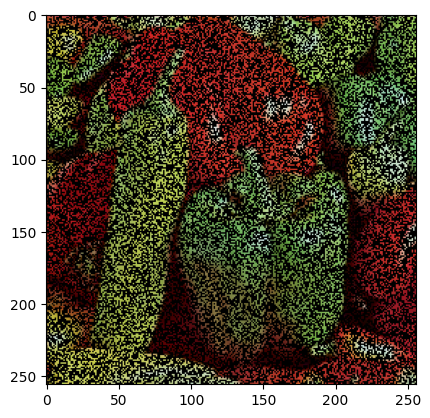

In [9]:
# Erase pixels
transformed_tensor, _ = generate_salt_pepper_noise(input_tensor, 0.6)

plt.imshow(transformed_tensor.permute(1, 2, 0))


print(f"Difference between original image and image with erased pixels, L2: "
        f"{np.linalg.norm(transformed_tensor - input_tensor)}")
predict(transformed_tensor.unsqueeze(0))


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


Difference between generated and original images, L2: 264.932861328125
Predicted class: velvet


'velvet'

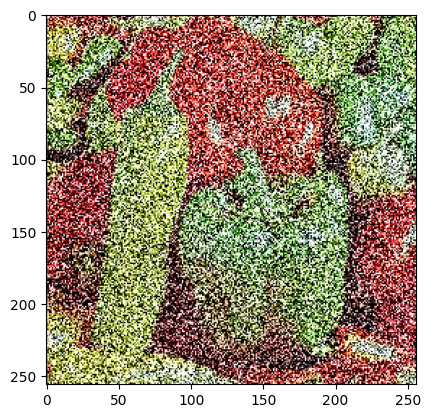

In [8]:
# White noise
transformed_tensor = generate_white_noise(input_tensor, 0.6)

plt.imshow(transformed_tensor.permute(1, 2, 0))


print(f"Difference between generated and original images, L2: "
        f"{np.linalg.norm(transformed_tensor - input_tensor)}")
predict(transformed_tensor.unsqueeze(0))


Difference between original image and image with erased pixels, L2: 101.9794921875
Predicted class: envelope


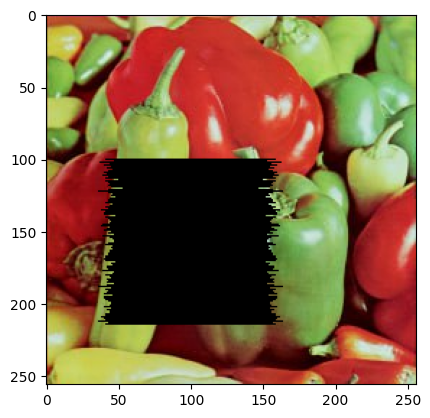

In [7]:
transformed_tensor = generate_patch_noise(input_tensor, 0.2)


plt.imshow(transformed_tensor.permute(1, 2, 0))


print(f"Difference between original image and image with erased pixels, L2: "
        f"{np.linalg.norm(transformed_tensor - input_tensor)}")
predict(transformed_tensor.unsqueeze(0))

## Adversarial attack (FGSM) on image

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


Predicted class: pillow
Difference between adversarial and original images, L2: 173.81753540039062


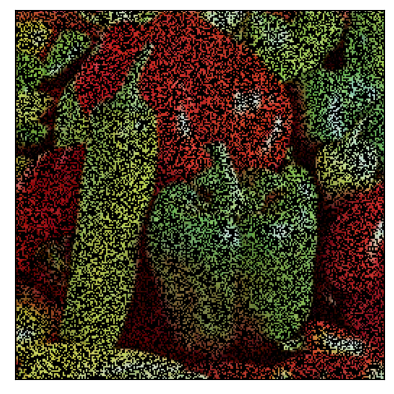

In [25]:
epsilon = 0.03

input_tensor.requires_grad = True
input_tensor.grad = None
model.eval()

output = model(input_tensor.unsqueeze(0))
_, pred = torch.max(output, 1)
loss = torch.nn.functional.cross_entropy(output, pred)
loss.backward()

adv_sample  = input_tensor + epsilon * input_tensor.grad.sign()
predict(adv_sample.unsqueeze(0))
transformed_tensor, _ = generate_salt_pepper_noise(adv_sample.detach().numpy(), 0.6)

plt.xticks([])
plt.yticks([])
with torch.no_grad():
    plt.imshow(transformed_tensor.transpose(1, 2, 0))
print(f"Difference between adversarial and original images, L2: "
        f"{np.linalg.norm(adv_sample.detach().numpy() - input_tensor.detach().numpy())}")
input_tensor.requires_grad = False


## 

## Denoising of adversarial attacks 

In [4]:
from tqdm import tqdm
from tensorly.decomposition import parafac
from tensorly.decomposition import tucker
import tensorly as tl
from skimage.filters import gaussian
from torch.linalg import svd
from skimage.metrics import peak_signal_noise_ratio

In [36]:
def tucker_decomposition(X_):
    core, tucker_factors = tucker(
        X_.numpy(), rank=[20], init="random", tol=10e-5)
    Y = tl.tucker_to_tensor((core, tucker_factors))
    return Y


def svd_decomposition(X_, rank=70):
    u, sig, vh = svd(X_, full_matrices=False)
    return u[:,:rank] @ torch.diag(sig[:rank]) @ vh[:rank,:]

def generate_salt_pepper_noise(img, ratio=0.001):
    # Create an array of ones
    height = img.shape[-2] 
    width = img.shape[-1]

    mask = np.ones((height,width))
    # Calculate how many elements we want to change to zero
    num_zeros = int(mask.size * ratio)
    # Generate random indices where we want to change ones to zeros
    indices_to_change = np.random.choice(mask.size, num_zeros, replace=False)
    # Change ones to zeros at those indices
    mask[indices_to_change % height, indices_to_change // height] = 0
    return img * mask, mask

In [37]:
def reconstruct(adv_sample, noise_persent = 0.5):
    with torch.no_grad():
        I_flatten = torch.cat([adv_sample[0], adv_sample[1], adv_sample[2]], dim=1)
        B_Miss, mask = generate_salt_pepper_noise(I_flatten, noise_persent)
        B_Miss = B_Miss.to(device)
        rev_mask = (mask - 1) * (-1)
        rev_mask_torch = torch.Tensor(rev_mask).to(device)
        X = B_Miss.detach().clone().to(device)

        for _ in range(30):
            Y = svd_decomposition(X, rank=70).to(device)
            X = B_Miss + rev_mask_torch * Y
            X = torch.Tensor(gaussian(X.detach().to('cpu').numpy(), 0.7, mode='nearest',truncate=2)).to(device)
            #bar.set_description(
            #    f"PSNR between reconstructed and original images: {peak_signal_noise_ratio(I_flatten.detach().numpy(), X.detach().numpy())}")
    X = X.clip(0,1)
    
    return torch.Tensor(torch.stack([X[:, :adv_sample.shape[2]],
                                     X[:,adv_sample.shape[2]:adv_sample.shape[2]*2],
                                     X[:,adv_sample.shape[2]*2:]]))

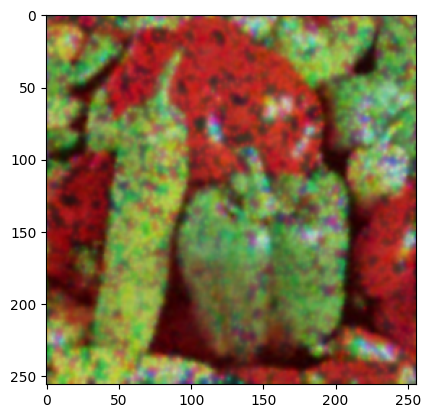

In [63]:
import matplotlib.pyplot as plt

X_ = reconstruct(input_tensor,0.9)
plt.imshow(X_.detach().numpy().transpose(1, 2, 0))

In [64]:
predict(X_.unsqueeze(0))

Predicted class: chiton


'chiton'

In [295]:
from numpy.linalg import svd
from copy import deepcopy

def FGSM(X_,  epsilon = 0.005):
    with torch.enable_grad():
        output = model(X_.unsqueeze(0))
        _, pred = torch.max(output, 1)
        loss = torch.nn.functional.cross_entropy(output, pred)
        loss.backward()
        adv_sample  = X_ + epsilon * X_.grad.sign()
    return adv_sample

correct = 0
for j in (bar := tqdm(range(150))):
    # Erase pixels
    adv_sample = FGSM(input_tensor, 0.03)
    I = adv_sample.detach().numpy()

    _, mask = generate_salt_pepper_noise(adv_sample, 0.6)
    rev_mask = np.abs((mask - 1)*(-1)).astype(int)

    B_Miss = torch.Tensor(I * mask)
    #X = deepcopy(B_Miss)
    #B_Miss = torch.Tensor(B_Miss)
    rev_mask_torch = torch.Tensor(rev_mask)

    X = deepcopy(B_Miss)
    for i in range(3):
        for _ in range(50):
            X[i] = torch.Tensor(X[i])
            Y = torch.Tensor(svd_decomposition(X[i]))

            X[i] = B_Miss[i] + rev_mask_torch * Y
            X[i] = torch.Tensor(cv2.GaussianBlur(X[i].detach().numpy(), ksize=(7,7), sigmaX=1.3))
            X[i] = (X[i] - X[i].min()) / (X[i].max() - X[i].min())
    
    # 'bell pepper'
    if predict(X.unsqueeze(0)) == 'sports car':
        correct +=1
    else:
        print(predict(X.unsqueeze(0)))
    bar.set_description(f"Accuracy: {correct / (j+1)}. Dist between orig and adv: {np.linalg.norm(input_tensor - adv_sample)}")
print(f"Total accuracy: {correct / 150}")

Accuracy: 0.0. Dist between orig and adv: 11.638898849487305:   1%|▋                                                                                                       | 1/150 [00:00<00:43,  3.45it/s]

tractor


Accuracy: 0.0. Dist between orig and adv: 11.638898849487305:   1%|█▍                                                                                                      | 2/150 [00:00<00:41,  3.54it/s]

race car


Accuracy: 0.0. Dist between orig and adv: 11.638898849487305:   2%|██                                                                                                      | 3/150 [00:00<00:43,  3.41it/s]

race car


... (45 outputs left out)

race car


Accuracy: 0.0. Dist between orig and adv: 11.638898849487305:  18%|██████████████████▌                                                                                    | 27/150 [00:07<00:35,  3.42it/s]

race car


KeyboardInterrupt: 

In [106]:
X_ = X.clip(0,1)
#X_ = adjust_sharpness(X, sharpness_factor=2)
img_sav = (X_.detach().numpy())
plt.imsave("recovered_peppers_clip.bmp", img_sav.transpose(1, 2, 0))

X_ = (X - X.min()) / (X.max() - X.min())
#X_ = adjust_sharpness(X, sharpness_factor=2)
img_sav = (X_.detach().numpy())
plt.imsave("recovered_peppers_scaled.bmp", img_sav.transpose(1, 2, 0))

X_ = (X - X.min()) / (X.max() - X.min())
X_ = adjust_sharpness(X, sharpness_factor=2)
img_sav = (X_.detach().numpy())
plt.imsave("recovered_peppers_scaled_sharpened.bmp", img_sav.transpose(1, 2, 0))


In [ ]:
epsilon = 0.005

input_tensor.requires_grad = True
            
model.eval()

output = model(input_tensor.unsqueeze(0))
_, pred = torch.max(output, 1)
loss = torch.nn.functional.cross_entropy(output, pred)
loss.backward()

adv_sample  = input_tensor + epsilon * input_tensor.grad.sign()
predict(adv_sample.unsqueeze(0))

with torch.no_grad():
    plt.imshow(adv_sample.permute(1, 2, 0))

print(f"Difference between adversarial and original images, L2: "
        f"{np.linalg.norm(adv_sample.detach().numpy() - input_tensor.detach().numpy())}")

In [ ]:
!pip3.11 install tensorly

/opt/homebrew/lib/python3.11/site-packages/tensorly/tucker_tensor.py:432: RuntimeWarning: Given only one int for 'rank' for decomposition a tensor of order 3. Using this rank for all modes.
  warnings.warn(message, RuntimeWarning)


30 (30, 3) <class 'list'>


/opt/homebrew/lib/python3.11/site-packages/IPython/core/pylabtools.py:152: MatplotlibDeprecationWarning: savefig() got unexpected keyword argument "orientation" which is no longer supported as of 3.3 and will become an error two minor releases later
  fig.canvas.print_figure(bytes_io, **kw)
/opt/homebrew/lib/python3.11/site-packages/IPython/core/pylabtools.py:152: MatplotlibDeprecationWarning: savefig() got unexpected keyword argument "facecolor" which is no longer supported as of 3.3 and will become an error two minor releases later
  fig.canvas.print_figure(bytes_io, **kw)
/opt/homebrew/lib/python3.11/site-packages/IPython/core/pylabtools.py:152: MatplotlibDeprecationWarning: savefig() got unexpected keyword argument "edgecolor" which is no longer supported as of 3.3 and will become an error two minor releases later
  fig.canvas.print_figure(bytes_io, **kw)
/opt/homebrew/lib/python3.11/site-packages/IPython/core/pylabtools.py:152: MatplotlibDeprecationWarning: savefig() got unexpecte

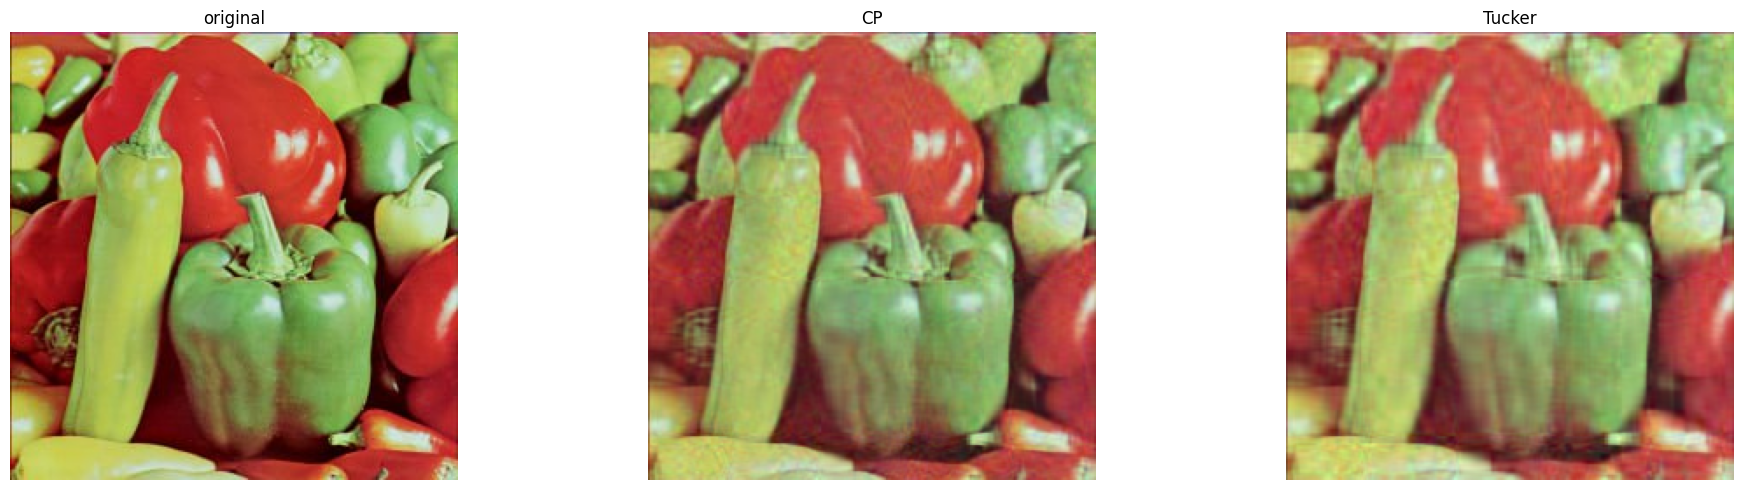

In [ ]:
import matplotlib.pyplot as plt
import tensorly as tl
import numpy as np
from scipy.misc import face
from scipy.ndimage import zoom
from tensorly.decomposition import parafac
from tensorly.decomposition import tucker
from math import ceil


random_state = 12345


def to_image(tensor):
    """A convenience function to convert from a float dtype back to uint8"""
    im = tl.to_numpy(tensor)
    im -= im.min()
    im /= im.max()
    im *= 255
    return im.astype(np.uint8)


image = tl.tensor(to_image(input_tensor.detach().permute(1, 2, 0).numpy()), dtype="float64")


# Rank of the CP decomposition
cp_rank = 50
# Rank of the Tucker decomposition
tucker_rank = [6]

# Perform the CP decomposition
weights, factors = parafac(image, rank=cp_rank, init="random", tol=10e-6)
# Reconstruct the image from the factors
cp_reconstruction = tl.cp_to_tensor((weights, factors))

# Tucker decomposition
core, tucker_factors = tucker(
    image, rank=30, init="random", tol=10e-5, random_state=random_state
)
print(len(core), core[0].shape, type(tucker_factors))
tucker_reconstruction = tl.tucker_to_tensor((core, tucker_factors))

# Plotting the original and reconstruction from the decompositions
fig = plt.figure()
fig.set_size_inches(20,5)
ax = fig.add_subplot(1, 3, 1)
ax.set_axis_off()
ax.imshow(to_image(image))
ax.set_title("original")

ax = fig.add_subplot(1, 3, 2)
ax.set_axis_off()
ax.imshow(to_image(cp_reconstruction))
ax.set_title("CP")

ax = fig.add_subplot(1, 3, 3)
ax.set_axis_off()
ax.imshow(to_image(tucker_reconstruction))
ax.set_title("Tucker")

plt.tight_layout()
plt.show()